# Plot figures for the manuscript

In [1]:
import networkx as nx
import pandas as pd
import numpy as np
from collections import defaultdict

import matplotlib.pyplot as plt
import json
import cmcrameri.cm as cmc
#import geopandas as gpd
import matplotlib
matplotlib.rc('font',**{'family':'sans-serif','sans-serif':['Helvetica']})
matplotlib.rcParams['pdf.fonttype'] = 42
#%matplotlib notebook
#%matplotlib widget
%matplotlib inline

# Fig 1
### panel a

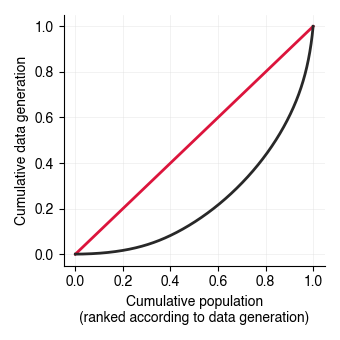

In [2]:
# load data
dat = pd.read_csv('figure_data_from_Katinka/Lorenz_curves/NYC_dataDistr_lorenz_values.csv',names=['cumsum'])

# count how many datapoints we have
norm_dat = dat.shape[0]

plt.figure(figsize=(3.4,3.4))
ax = plt.subplot(111)
# plot cumulative sum
plt.plot(np.linspace(0.0, 1.0, norm_dat), dat['cumsum'], color='#282828', lw=2,zorder=3)
# plot diagonal
plt.plot([0,1], [0,1], lw=2, c='crimson',zorder=2)
plt.xlabel(f'Cumulative population\n(ranked according to data generation)')
plt.ylabel(f'Cumulative data generation')

plt.grid('on',color='#dcdcdc',lw=0.5,alpha=0.5,zorder=1)
ax.spines[['right', 'top']].set_visible(False)
plt.tight_layout()

#plt.savefig("plots/main_plots/Fig1a.pdf")
plt.show()

### Panel b is a table made in illustrator

In [15]:
# pass

### Panels c & d
Correlations in travel networks
Node correlations (nodes are census tracts)
<br/>
Edge weight correlations (edges are trips between census tracts)

In [3]:
# data was preprocessed in a way that included all trips for people living in NYC, 
# but they can take trips outside the city. Here we filter outside trips away
# Filter trips and keep only edges where both endpoints are in NYC.
NYC_boroughs = set(['US.NY.085','US.NY.081','US.NY.061','US.NY.047','US.NY.005'])
NYC_counties = set(['085','081','061','047','005'])
# new york county 061 - manhattan
# queens county 081 - queens
# richmond county 086 - staten island
# kings county 047 - brooklyn
# bronx county 005 - bronx 

disregard = set(['US.NY.085.990100']) # this is a water census tract, people travel to a from it (using boats?)
# since nobody lives there we remove it 

In [4]:
# containers to store edge info
networks = dict()

# iterate over groups (Q1 most data, Q20 lowest data)
for q in range(1,20+1):
    edges = defaultdict(int)
    with open('NW_data_2019/NW%02d_NYC_2019_04_edges.csv' % q) as f:
        next(f) # skip first line
        for line in f:
            i,j,w = line.split(',')
            # check if both are in NYC
            if (i[:9] in NYC_boroughs) and (j[:9] in NYC_boroughs):
                i = i[:-2] # upscale data to census tracts by removing block group info
                j = j[:-2] # upscale data to census tracts by removing block group info
                if (i not in disregard) and (j not in disregard):
                    edges[(min(i,j),max(i,j))] += int(w)
    
    # transform into network
    networks[q] = nx.Graph()
    #networks[q].add_weighted_edges_from([(i,j,w) for (i,j),w in edges.items()]) # all edges
    networks[q].add_weighted_edges_from([(i,j,w) for (i,j),w in edges.items() if w > 1]) # threshold weak edges
    #networks[q].add_weighted_edges_from([(i,j,w) for (i,j),w in edges.items() if w >= 5]) # threshold weak edges
    #networks[q].add_weighted_edges_from([(i,j,w) for (i,j),w in edges.items() if w >= 10]) # threshold weak edges
    

In [7]:
from scipy.stats import pearsonr, spearmanr

# calculate node degree correlations
R_pearson = []
#R_spearman = []
# go through groups and calculate degree correlations
for q in range(1,20+1):
    # cal culate joint nodes
    joint_nodes = set(networks[1].nodes()).union(networks[q].nodes())
    #joint_nodes = set(networks[1].nodes()).intersection(networks[q].nodes())
    # preload degrees
    n_1 = dict(nx.degree(networks[1])) 
    n_q = dict(nx.degree(networks[q]))
    #n_1 = dict(nx.degree(networks[1], weight='weight'))
    #n_q = dict(nx.degree(networks[q], weight='weight'))
    # find degrees of joint nodes
    x,y = zip(*[(n_1.get(n,0),n_q.get(n,0)) for n in joint_nodes])
    # calculate correlations
    R_pearson.append(pearsonr(x,y)[0])
    #R_spearman.append(spearmanr(x,y)[0])

# go through groups and calculate edge weight correlations
R_e_pearson = []
#R_e_spearman = []
for q in range(1,20+1):
    # calculate joint nodes
    joint_edges = set(networks[1].edges()).union(networks[q].edges())
    #joint_edges = set(networks[1].edges()).intersection(networks[q].edges())
    # preload degrees
    e_1 = dict([((i,j),w['weight']) for i,j,w in networks[1].edges(data=True)])
    e_q = dict([((i,j),w['weight']) for i,j,w in networks[q].edges(data=True)])
    #n_1 = dict(nx.degree(networks[1], weight='weight'))
    #n_q = dict(nx.degree(networks[q], weight='weight'))
    # find degrees of joint nodes
    x,y = zip(*[(e_1.get(e,0),e_q.get(e,0)) for e in joint_edges])
    # calculate correlations
    R_e_pearson.append(pearsonr(x,y)[0])
    #R_e_spearman.append(spearmanr(x,y)[0])

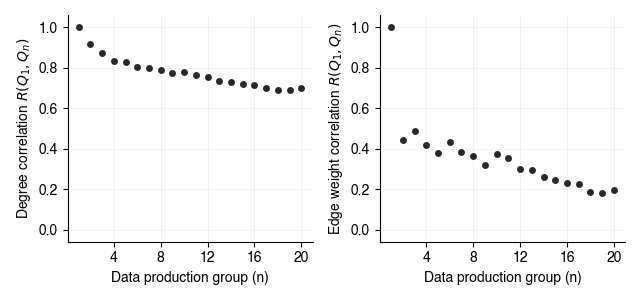

In [11]:
plt.figure(figsize=(6.4,3))
ax = plt.subplot(121)
plt.plot(range(1,20+1),R_pearson,'o',color='#282828',markeredgecolor='white')
#plt.plot(range(1,20+1),R_spearman,'o',color='#282828',markeredgecolor='white')

plt.xlabel('Data production group (n)')
plt.ylabel(r'Degree correlation $R(Q_1,Q_n)$')
plt.xticks(range(4,20+1,4))

plt.grid('on',color='#dcdcdc',lw=0.5,alpha=0.5,zorder=2)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.ylim(-0.06,1.06)

ax = plt.subplot(122)
plt.plot(range(1,20+1),R_e_pearson,'o',color='#282828',markeredgecolor='white')
#plt.plot(range(1,20+1),R_e_spearman,'o',color='#282828',markeredgecolor='white')

plt.xlabel('Data production group (n)')
plt.ylabel(r'Edge weight correlation $R(Q_1,Q_n)$')
plt.xticks(range(4,20+1,4))
plt.ylim(-0.06,1.06)

plt.grid('on',color='#dcdcdc',lw=0.5,alpha=0.5,zorder=2)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.tight_layout()

plt.show()
#plt.savefig('plots/main_plots/Fig1cd_threshold=0.pdf')
#plt.savefig('plots/main_plots/Fig1cd_threshold=0_intersection.pdf')
#plt.savefig('plots/main_plots/Fig1cd_threshold=1.pdf')
#plt.savefig('plots/main_plots/Fig1cd_threshold=5.pdf')
#plt.savefig('plots/main_plots/Fig1cd_threshold=10.pdf')

# Fig 2

### a - Shap plot for NYC
There is something off with the way the SHAP library was saving the plotting the data - matplotlib was unable to save the figures as pdf's. I could not fix it, so I made my own plotter.

In [271]:
#import shap

In [272]:
# FOR NYC
# load data for shap plot
SHAP_vals = pd.read_csv('figure_data_from_Katinka/SHAP_plots/NYC_SHAP_vals.csv')
X_feature_vals = pd.read_csv('figure_data_from_Katinka/SHAP_plots/NYC_X_feature_vals.csv')

# NYC order => manual order
manu_order = ["black", "poverty", "white", "asian", "50-64", "18-29", "65+", "other", "30-49", "academic", "<18", "female"]
manu_colnames = ["black (%)", "poverty (%)", "white (%)", "asian (%)", "50-64 (%)", "18-29 (%)", "65+ (%)", 
                 "other (%)\nethnicity", "30-49 (%)", "academical (%)\ndegree", "<18 (%)", "female (%)"]

# Selection columns for small version SHAP plot
manu_order_s = ["black", "poverty", "white", "asian", "other", "academic"]
manu_colnames_s = ["black (%)", "poverty (%)", "white (%)", "asian (%)", "other (%)\nethnicity", "academical (%)\ndegree"]

SHAP_vals = SHAP_vals[manu_order_s]
X_feature_vals = X_feature_vals[manu_order_s]

In [273]:
# i had issues with the shap package so had to make my own
def shap_like_plot(shap_vals,feature_vals):
    # bin shap_vals to unpack them vertically 
    bin_no = 50
    #bins = np.linspace(min(shap_vals),max(shap_vals),bins+1)
    v,bins=np.histogram(shap_vals,bins=bin_no)
    # find which datapoints belong to which bins
    bin_indexes = np.digitize(shap_vals,bins=bins,right=False)

    # create histogram
    v,_=np.histogram(shap_vals,bins=bins)
    max_y_width = 0.4
    max_bin = max(v) # use this as relative scale

    # create randomized y-values depending on the bins
    y_vals = []
    for bi in bin_indexes:
        if bi>bin_no:
            bi = bin_no
        y_vals.append(np.random.uniform(low=-max_y_width*(v[bi-1]/max_bin), high=max_y_width*(v[bi-1]/max_bin)))

    # handle colors
    # trim values to trim the color range
    f_max = np.nanpercentile(feature_vals, 95)
    f_min = np.nanpercentile(feature_vals, 5)
    # trim features ranges
    feature_vals = [min(f,f_max) for f in feature_vals]
    feature_vals = np.array([max(f,f_min) for f in feature_vals])
    # min max scale values to make it easier to control the colorbar
    feature_vals = np.round(20*(feature_vals-min(feature_vals))/(max(feature_vals)-min(feature_vals)),0)
    colors = plt.cm.coolwarm(np.linspace(0,1,21))
    colors = [colors[int(i)] for i in feature_vals]

    return y_vals,colors, feature_vals+2

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


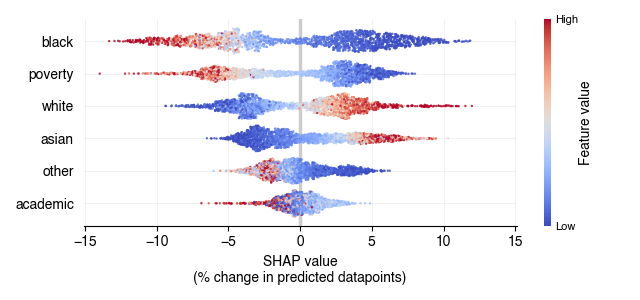

In [274]:
plt.figure(figsize=(6.4,3))
# plot SHAP values
for i,var in enumerate(SHAP_vals.columns):
    y,c,z = shap_like_plot(SHAP_vals[var],X_feature_vals[var])
    #for ii in range(len(y)):
    #    plt.scatter(SHAP_vals[var][ii],i+y[ii],color=c[ii],s=4,zorder=int(z[ii]))
    plt.scatter(np.array(SHAP_vals[var]),i+np.array(y),color=c,s=3,zorder=3,alpha=0.8, edgecolors='none')

ax = plt.gca()
m = plt.cm.ScalarMappable(cmap=plt.cm.coolwarm)
m.set_array([0, 1])
cb = plt.colorbar(m,ticks=[0, 1], aspect=30, ax=ax)
cb.set_ticklabels(["Low", "High"],color='black',fontproperties="Helvetica")
cb.set_label("Feature value", fontsize=10, labelpad=0,color='black',fontproperties="Helvetica")
cb.ax.tick_params(labelsize=8, length=0)
cb.set_alpha(1)
cb.outline.set_visible(False)
plt.axvline(x=0,color='#cccccc',lw=2.5,zorder=2)

plt.xlim(-15.1, 15.1)
plt.grid(color='#dcdcdc',lw=0.5,alpha=0.5,zorder=1)
plt.xlabel('SHAP value\n(% change in predicted datapoints)',fontsize=10,fontproperties='Helvetica')
plt.xticks(fontsize=8,fontproperties='Helvetica')
plt.yticks(range(len(SHAP_vals.columns)),list(SHAP_vals.columns),fontsize=10,fontproperties='Helvetica')

ax.spines[['right', 'top', 'left']].set_visible(False)
plt.tick_params(left = False)
ax.invert_yaxis()

plt.tight_layout()
plt.savefig('plots/main_plots/fig2a.pdf',bbox_inches='tight')
plt.show()

### subplots b-j

In [98]:
plt.figure(figsize=(6,6))
p_i = 1
for city in ['LA','Chicago','Houston','Phoenix','Philadelphia','San_Antonio','San_Diego','Dallas','San_Jose']: # plot SHAP values
    plt.subplot(3,3,p_i)
    # load data for shap plot
    SHAP_vals = pd.read_csv(f'figure_data_from_Katinka/SHAP_plots/{city}_SHAP_vals.csv')
    X_feature_vals = pd.read_csv(f'figure_data_from_Katinka/SHAP_plots/{city}_X_feature_vals.csv')
    # select features
    SHAP_vals = SHAP_vals[manu_order_s]
    X_feature_vals = X_feature_vals[manu_order_s]
    
    for i,var in enumerate(SHAP_vals.columns):
        y,c,z = shap_like_plot(SHAP_vals[var],X_feature_vals[var])
        plt.scatter(np.array(SHAP_vals[var]),i+np.array(y),color=c,s=3,zorder=3,alpha=0.8, edgecolors='none')

    ax = plt.gca()
    plt.grid(color='#dcdcdc',lw=0.5,alpha=0.5,zorder=3)

    ax.spines[['right', 'top', 'left']].set_visible(False)
    plt.tick_params(left = False)
    ax.invert_yaxis()
    
    plt.title(city.replace('_',' ').replace('LA','Los Angeles'),fontsize=9)
    #plt.text(0.7,0.9,city.replace('_',' '),fontsize=9,transform = ax.transAxes)
    if p_i >= 7:
        plt.xlabel('SHAP value',fontsize=10,fontproperties='Helvetica')
        plt.xticks(range(-20,21,10),fontsize=8,fontproperties='Helvetica')
    else:
        #ax.set_xticklabels([])
        plt.xticks(range(-20,21,10),['']*5)
        #ax.xaxis.set_major_locator(range(-20,21,10))
        ax.xaxis.label.set_visible(False)
        
    if p_i%3 == 1:
        plt.yticks(range(len(SHAP_vals.columns)),list(SHAP_vals.columns),fontsize=12,fontproperties='Helvetica')
    else:
        ax.set_yticklabels([])
        ax.yaxis.label.set_visible(False)
    p_i += 1

    ax.set_xlim(-26, 26) 
    
plt.tight_layout()
plt.savefig('plots/main_plots/fig2b-j.pdf',bbox_inches='tight')
plt.close()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


# Fig 3
### a - matrix of R2 values - build model on one city and test on other

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


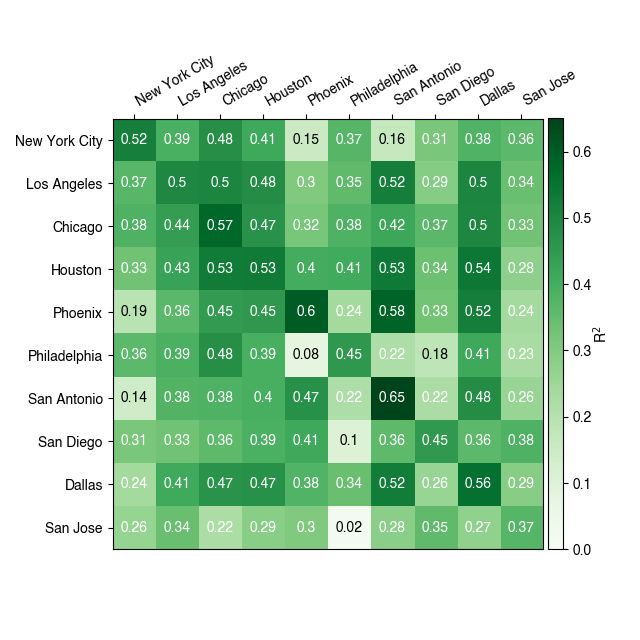

In [12]:
# load data
dat = pd.read_csv('figure_data_from_Katinka/CityComp_Matrix/CityComp_Matrix.csv')
cities = ['New York City','Los Angeles','Chicago', 'Houston', 'Phoenix', 'Philadelphia',
       'San Antonio', 'San Diego', 'Dallas', 'San Jose']
X = dat.values[:,1:].astype(float) # matrix for plotting

# create figure and plot data 
plt.figure(figsize=(6.4,6.4))
ax = plt.subplot(111)
#plt.imshow(X,cmap=cmc.batlowK,vmin=0,vmax=0.65)
plt.imshow(X,cmap=plt.cm.Greens,vmin=0,vmax=0.65)
cb = plt.colorbar(aspect=30,shrink=0.74,pad=0.01)
plt.xticks(range(10),cities,rotation=30,ha='left')
plt.yticks(range(10),cities)
ax.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
cb.set_label("R$^2$", fontsize=10, labelpad=0,color='black',fontproperties="Helvetica")

# add text annotations
for i in range(10):
    for j in range(10):
        if X[i,j] < 0.20:
            text = plt.text(j, i, round(X[i, j],2),ha="center", va="center", color="black")
        else:
            text = plt.text(j, i, round(X[i, j],2),ha="center", va="center", color="w")

plt.tight_layout()
plt.savefig('plots/main_plots/fig3a.pdf',bbox_inches='tight')
plt.show()

### b - out of sample - train on 9 cites and test on 1

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


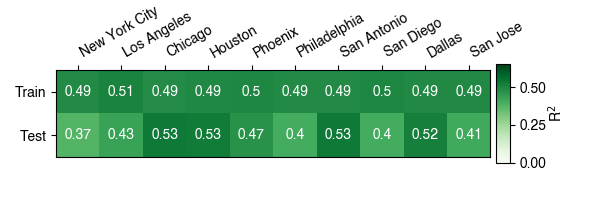

In [13]:
# load data
dat = pd.read_csv('figure_data_from_Katinka/R2s_leave1out/R2s_leave1out.csv')
X = dat.values.astype(float) # matrix for plotting
cities = ['New York City','Los Angeles','Chicago', 'Houston', 'Phoenix', 'Philadelphia',
       'San Antonio', 'San Diego', 'Dallas', 'San Jose']

# create figure and plot data
plt.figure(figsize=(5.9,2))
ax = plt.subplot(111)
plt.imshow(X,cmap=plt.cm.Greens,vmin=0,vmax=0.65)
cb = plt.colorbar(aspect=7,shrink=0.688,pad=0.01)
plt.xticks(range(10),cities,rotation=30,ha='left')
plt.yticks(range(2),['Train','Test'])
ax.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
cb.set_label("R$^2$", fontsize=10, labelpad=0,color='black',fontproperties="Helvetica")

# add text annotations
for i in range(2):
    for j in range(10):
        if X[i,j] < 0.20:
            text = plt.text(j, i, round(X[i, j],2),ha="center", va="center", color="black")
        else:
            text = plt.text(j, i, round(X[i, j],2),ha="center", va="center", color="w")

plt.tight_layout()
plt.savefig('plots/main_plots/fig3b.pdf',bbox_inches='tight')
plt.show()

There are issues in how matplotlib save figures. Here we save the same figure without any labels - these are assembled in illustrator.

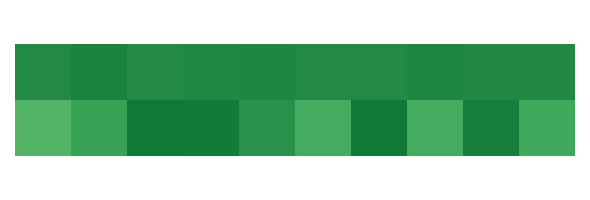

In [18]:
# load data
dat = pd.read_csv('figure_data_from_Katinka/R2s_leave1out/R2s_leave1out.csv')
X = dat.values.astype(float) # matrix for plotting
cities = ['New York City','Los Angeles','Chicago', 'Houston', 'Phoenix', 'Philadelphia',
       'San Antonio', 'San Diego', 'Dallas', 'San Jose']

# create figure and plot data
plt.figure(figsize=(5.9,2))
ax = plt.subplot(111)
plt.imshow(X,cmap=plt.cm.Greens,vmin=0,vmax=0.65)
ax.spines[['right', 'top', 'left','bottom']].set_visible(False)
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.savefig('plots/main_plots/fig3b-stupidity.png',bbox_inches='tight',dpi=300)
plt.show()